# Week 1 · Technical Demonstration
## What is AI? Coding as a creative medium
*AI for Creativity · Level 6*

Today we write our first program — and it makes **poetry and colour**. By the end you will have built a tiny *generative* artwork: a poem and a palette that are different every time you run it.

> Code is just another creative material — like clay, paint or light. Today we learn to hold it.

**How to use this notebook**

- Works in **Google Colab** (open via *File → Upload notebook*) and in **Jupyter Notebook / JupyterLab** (Anaconda).
- Run a cell with **Shift + Enter**. Run cells **top to bottom** — later cells use things made in earlier ones.
- Grey text starting with `#` is a *comment*: a note for humans. Python ignores it.
- Broke something? *Runtime → Restart* (Colab) or *Kernel → Restart* (Jupyter) and run from the top. You cannot break the computer.

---
## Part 1 · Talking to Python
`print()` shows something on screen. Text goes inside quotes — Python calls text a **string**.

In [1]:
print("Hello, creative world!")

Hello, creative world!


### Variables — labelled boxes
A **variable** is a labelled box that stores something so we can use it later. The `=` sign means *put this in the box*.

In [2]:
artist = "Beanse"
medium = "codododedo"
year = 2026

print(artist)
print("My medium is", medium)

Beanse
My medium is codododedo


### f-strings — mixing text and variables
Put an `f` before the quotes, then drop variables inside `{curly brackets}`.

In [3]:
print(f"{artist} works in {medium} and is exhibiting in {year}.")

Beanse works in codododedo and is exhibiting in 2026.


**Try it:** change `artist` and `medium` to describe *you*, then re-run the two cells above.

---
## Part 2 · Lists and chance
A **list** holds many items in order, inside square brackets `[ ]`. The `random` library lets the computer make choices — our first taste of *generative* art.

In [4]:
import random

subjects = ["the moon", "a paper crane", "my grandmother's kettle", "the city", "a neon sign"]
verbs    = ["whispers to", "forgets", "dances with", "paints", "waits for"]
objects  = ["the silent sea", "a borrowed colour", "the last train", "tomorrow", "an empty gallery"]

print(subjects)
print("How many subjects?", len(subjects))
print("The first subject is:", subjects[0])   # Python counts from 0!

['the moon', 'a paper crane', "my grandmother's kettle", 'the city', 'a neon sign']
How many subjects? 5
The first subject is: the moon


In [5]:
# random.choice picks one item from a list — run this cell several times
print(random.choice(subjects), random.choice(verbs), random.choice(objects))

a neon sign whispers to the silent sea


---
## Part 3 · Loops — repeating with variation
A `for` loop repeats the indented lines. Here: write **4 lines** of a poem. The indentation (4 spaces) tells Python which lines belong inside the loop.

In [6]:
print("~ Untitled (Generated) ~\n")

for line_number in range(4):
    line = f"{random.choice(subjects)} {random.choice(verbs)} {random.choice(objects)}"
    print(line.capitalize())

~ Untitled (Generated) ~

The moon dances with the silent sea
The moon dances with an empty gallery
A paper crane forgets tomorrow
My grandmother's kettle waits for a borrowed colour


### Our poem generator, tidied up
We collect the lines into a list so we can reuse the poem later (for our poster).

In [7]:
import random

def make_poem(n_lines=4):
    """Return a list of randomly generated poem lines."""
    poem = []
    for _ in range(n_lines):
        s = random.choice(subjects)
        v = random.choice(verbs)
        o = random.choice(objects)
        poem.append(f"{s} {v} {o}".capitalize())
    return poem

poem = make_poem()
for line in poem:
    print(line)

A paper crane paints an empty gallery
The moon paints the silent sea
The moon forgets the last train
A neon sign waits for an empty gallery


> 💡 `def` makes a **function** — a reusable recipe. We will study functions properly in Week 2; for now, notice it lets us make a new poem with one word: `make_poem()`.

---
## Part 4 · Colour is numbers too
Screens mix **Red, Green and Blue** light, each from **0 to 255**. Designers write these as a **hex code**: `#FF6B6B` = red FF (255), green 6B (107), blue 6B (107).

In [8]:
r, g, b = 255, 107, 107
hex_code = f"#{r:02X}{g:02X}{b:02X}"   # :02X means 'two-digit hexadecimal'
print(hex_code)

#FF6B6B


In [9]:
def random_colour():
    """Return a random hex colour like '#3A7FC1'."""
    r = random.randint(0, 255)
    g = random.randint(0, 255)
    b = random.randint(0, 255)
    return f"#{r:02X}{g:02X}{b:02X}"

palette = [random_colour() for _ in range(5)]
print(palette)

['#A52290', '#38AA50', '#DA029B', '#AFA1D0', '#AEC24D']


### Show the palette as swatches

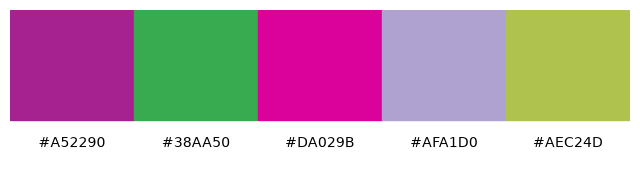

In [10]:
import matplotlib.pyplot as plt

def show_palette(colours):
    fig, ax = plt.subplots(figsize=(8, 2))
    for i, c in enumerate(colours):
        ax.add_patch(plt.Rectangle((i, 0), 1, 1, color=c))
        ax.text(i + 0.5, -0.15, c, ha="center", va="top", fontsize=10)
    ax.set_xlim(0, len(colours)); ax.set_ylim(-0.4, 1)
    ax.axis("off")
    plt.show()

show_palette(palette)

### Designing the randomness
Pure randomness is often ugly. Artists **constrain** chance. Here we only allow *warm* colours: lots of red, some green, little blue.

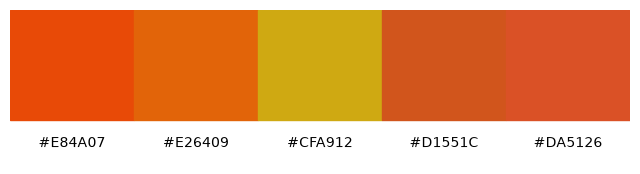

In [11]:
def warm_colour():
    r = random.randint(200, 255)
    g = random.randint(60, 180)
    b = random.randint(0, 90)
    return f"#{r:02X}{g:02X}{b:02X}"

show_palette([warm_colour() for _ in range(5)])

> This is the heart of generative design: **you write the rules, the machine explores the possibilities.**

---
## Part 5 · Bring it together — a generative poster

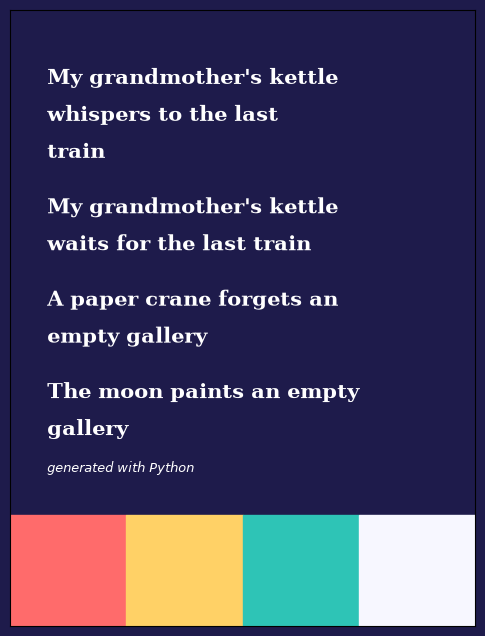

In [12]:
import textwrap

def make_poster(poem, colours, filename="my_poster.png"):
    fig, ax = plt.subplots(figsize=(6, 8), facecolor=colours[0])
    ax.set_facecolor(colours[0])
    for i, c in enumerate(colours[1:]):                 # colour bands at the bottom
        ax.add_patch(plt.Rectangle((i * 0.25, 0), 0.25, 0.18, color=c))
    y = 0.88
    for line in poem:                                   # the poem, wrapped to fit
        for part in textwrap.wrap(line, 24):
            ax.text(0.08, y, part, fontsize=15, color="white", fontweight="bold", family="serif")
            y -= 0.06
        y -= 0.03
    ax.text(0.08, 0.25, "generated with Python", fontsize=9, color="white", style="italic")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xticks([]); ax.set_yticks([])
    fig.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()

make_poster(make_poem(), ["#1E1B4B", "#FF6B6B", "#FFD166", "#2EC4B6", "#F7F7FF"])

Run the cell again — a new poem every time. The poster is saved as **my_poster.png** (in Colab: folder icon on the left).

---
## Part 6 · Errors are normal (and useful)
Every programmer sees errors all day. Read the **last line** of the red message first. Uncomment one line at a time (remove the `#`) and run:

In [13]:
# print("missing a quote)          # SyntaxError: the string never ends
# print(colour_palette)             # NameError: we never created 'colour_palette'
# subjects[10]                      # IndexError: the list only has 5 items (0–4)
print("Uncomment one line above to see an error, then put the # back.")

Uncomment one line above to see an error, then put the # back.


---
## Exit ticket ✍️
In the class channel, answer in one sentence: **"One thing AI could do for my discipline is…"**

In [14]:
def main():
  happy = True
  know_it = True

  print("If you're happy and you know it, clap your hands")

  if happy and know_it:
    clap_your_hands()

def clap_your_hands():
  print("*clap* *clap*")

if __name__ == "__main__":
  main()

If you're happy and you know it, clap your hands
*clap* *clap*
